## -------------------------------------------------------------------------------------------------------------------

# PROYECTO DEL CEIEC - Network Traffic Classification, en colaboración con Foqum
# Descripción del notebook: inferencia sobre un modelo existente y previamente entrenado. El modelo recibirá una serie de semiflujos y mostrará en qué categoría los clasifica
# Becario responsable del proyecto: Carlos Arranz Luque
# Directora de la investigación: Ana María Maitín López
# Fecha: curso académico 2022-2023

## -------------------------------------------------------------------------------------------------------------------

## Importación de librerías y módulos

In [1]:
import configparser
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize

## Módulos/scripts propios
from src import *

## Este código recarga los módulos/librerías antes de cada ejecución parcial del código, de tal forma
## que podemos cambiar una función en mitad de la ejecución y dichos cambios serán efectivos sin necesidad
## de recargar el kernel. Esto es útil cuando aún se está en fase de desarrollo y hay que verificar si las
## funciones tienen el comportamiento deseado
%load_ext autoreload
%autoreload 2

2023-07-08 23:41:34.548584: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## -------------------------------------------------------------------------------------------------------------------

## Opciones de ejecución e hiperparámetros

In [2]:
## Leemos el archivo "config.cfg" donde están las opciones de ejecución e hiperparámetros de la inferencia

config = configparser.RawConfigParser()
config.read('config/config_inferencia.cfg')

## Optenemos los valores de cada una de las subcategorías del archivo de configuración
opcionesEjecucion_dict = dict(config.items('OpcionesEjecucion'))

## De momento comentado a la espera de que se introduzcan hiperparámetros a la inferencia
# hiperparametros_dict = dict(config.items('Hiperparametros'))

rutasArchivos_dict = dict(config.items('RutasArchivos'))

In [3]:
### ----------------------------------------------------------------------------------------------
### ------------------------------ Opciones de ejecución -----------------------------------------
### ----------------------------------------------------------------------------------------------


# tipo_modelo                -->  Indica el modelo de clasificación que será utilizado 
#                                 Actualmente existe el Transformer (XFMR) y el LSTM
# hash_pesos_modelo          -->  Indica el hash del modelo cuyos pesos queremos cargar 
# hash_pesos_semiflujos      -->  Indica el hash de los semiflujos usados para entrenar el 
#                                 modelo cuyos pesos queremos cargar. (Debe existir la combinación 
#                                 de modelo y semiflujos en el directorio de pesos correspondiente)
# hash_semiflujos_a_inferir  -->  Indica el hash de los semiflujos que se usarán para realizar
#                                 la inferencia. (Deben existir en la ruta de semiflujos)

tipo_modelo = opcionesEjecucion_dict['tipo_modelo']

hash_pesos_modelo = opcionesEjecucion_dict['hash_pesos_modelo']

hash_pesos_semiflujos = opcionesEjecucion_dict['hash_pesos_semiflujos']

hash_semiflujos_a_inferir = opcionesEjecucion_dict['hash_semiflujos_a_inferir']



### ----------------------------------------------------------------------------------------------
### --------------------------------- Hiperparámetros --------------------------------------------
### ----------------------------------------------------------------------------------------------

## De momento vacío, ya que no se han introducido hiperparámetros a la inferencia


### ----------------------------------------------------------------------------------------------
### ----------------------------------- Rutas archivos -------------------------------------------
### ----------------------------------------------------------------------------------------------

# En "rutaSemiflujos" tenemos el directorio que almacena los semiflujos
# En "rutaPesosXFMR" tenemos el directorio que almacena los pesos del Transformer
# En "rutaPesosLSTM" tenemos el directorio que almacena los pesos de la LSTM
# En "rutaConfigXFMR" tenemos el directorio que almacena los archivos de configuración de los modelos Transformer
# En "rutaConfigLSTM" tenemos el directorio que almacena los archivos de configuración de los modelos LSTM

rutaSemiflujos = rutasArchivos_dict["rutasemiflujos"]
rutaPesosXFMR = rutasArchivos_dict["rutapesosxfmr"]
rutaPesosLSTM = rutasArchivos_dict["rutapesoslstm"]
rutaConfigXFMR = rutasArchivos_dict["rutaconfigxfmr"]
rutaConfigLSTM = rutasArchivos_dict["rutaconfiglstm"]

## -------------------------------------------------------------------------------------------------------------------

## Mostramos los parámetros leídos del archivo de configuración 
### (Así nos cercioramos qué ha leído el programa y evitamos errores de configuración)

In [4]:
print("Parámetros leídos del archivo de configuración: \n")
print("Tipo de modelo = "+tipo_modelo)
print("Hash pesos modelo = "+hash_pesos_modelo)
print("Hash pesos semiflujos = "+hash_pesos_semiflujos)
print("Hash semiflujos a inferir= "+hash_semiflujos_a_inferir)

print("Ruta semiflujos = "+rutaSemiflujos)
print("Ruta pesos Transformer = "+rutaPesosXFMR)
print("Ruta pesos LSTM = "+rutaPesosLSTM)
print("Ruta configuracion Transformer = "+rutaConfigXFMR)
print("Ruta configuracion LSTM = "+rutaConfigLSTM)


Parámetros leídos del archivo de configuración: 

Tipo de modelo = XFMR
Hash pesos modelo = 5717c14b446a100bd726004bc4cbb4ee
Hash pesos semiflujos = 7be2a6d0f3592295547184340b68b4b4
Hash semiflujos a inferir= 69030d838c4905d7676c33f72c82aacc
Ruta semiflujos = Objetos preprocesados/Semiflujos/
Ruta pesos Transformer = Objetos preprocesados/Pesos_TransformerSimple/
Ruta pesos LSTM = Objetos preprocesados/Pesos_LSTM/
Ruta configuracion Transformer = Resultados/Resultados_TransformerSimple/Archivos de configuracion/
Ruta configuracion LSTM = Resultados/Resultados_LSTM/Archivos de configuracion/


## -------------------------------------------------------------------------------------------------------------------

## Generamos el modelo indicado

## -------------------------------------------------------------------------------------------------------------------

In [5]:
## Llamamos a la función que nos devuelve todos los datos necesarios para reconstruir el modelo indicado

if (tipo_modelo == "LSTM"):
    print("Obteniendo parámetros del modelo LSTM...")
    num_capas_lstm,hidden_state,mlp_units,lstm_dropout,mlp_dropout,batch_size,learning_rate,normalizar,\
    n_clases,clases_clasificador,input_shape = obtener_hiperparametros_LSTM(rutaConfigLSTM,hash_pesos_modelo,hash_pesos_semiflujos,rutaSemiflujos)
elif(tipo_modelo == "XFMR"):
    print("Obteniendo parámetros del modelo XFMR...")
    batch_size,learning_rate,positional_encoding,num_heads,head_size,mlp_units,ff_dim,mlp_dropout,dropout,\
    num_capas_atencion,normalizar,n_clases,clases_clasificador,input_shape = obtener_hiperparametros_XFMR(rutaConfigXFMR,hash_pesos_modelo,hash_pesos_semiflujos,rutaSemiflujos)
else:
    print("\n¡¡ERROR!!\nIntroduce un tipo de modelo correcto en el archivo de configuracion")

Obteniendo parámetros del modelo XFMR...


In [6]:
## Reconstruimos el modelo indicado

if (tipo_modelo == "LSTM"):
    print("Reconstruyendo el modelo LSTM...")
    model = reconstruir_LSTM(num_capas_lstm,hidden_state,mlp_units,lstm_dropout,mlp_dropout,learning_rate,\
                     n_clases,input_shape,hash_pesos_semiflujos,hash_pesos_modelo,rutaPesosLSTM)
elif(tipo_modelo == "XFMR"):
    print("Reconstruyendo el modelo XFMR...")
    model = reconstruir_XFMR(n_clases,learning_rate,positional_encoding,num_heads,head_size,mlp_units,ff_dim,\
                             mlp_dropout,dropout,num_capas_atencion,input_shape,hash_pesos_semiflujos,hash_pesos_modelo,rutaPesosXFMR)
    

Reconstruyendo el modelo XFMR...


2023-07-08 23:41:35.582188: E tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:266] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
2023-07-08 23:41:35.582204: I tensorflow/compiler/xla/stream_executor/cuda/cuda_diagnostics.cc:168] retrieving CUDA diagnostic information for host: docker_carlos
2023-07-08 23:41:35.582207: I tensorflow/compiler/xla/stream_executor/cuda/cuda_diagnostics.cc:175] hostname: docker_carlos
2023-07-08 23:41:35.582282: I tensorflow/compiler/xla/stream_executor/cuda/cuda_diagnostics.cc:199] libcuda reported version is: NOT_FOUND: was unable to find libcuda.so DSO loaded into this program
2023-07-08 23:41:35.582296: I tensorflow/compiler/xla/stream_executor/cuda/cuda_diagnostics.cc:203] kernel reported version is: 535.54.3


## -------------------------------------------------------------------------------------------------------------------

## Cargar semiflujos y datos relacionados

In [7]:
## Cargamos todos los datos relacionados con el hash de semiflujos a clasificar proporcionado 
## en el archivo de configuración. Estos datos son:
##     - El propio array con los semiflujos
##     - El array de etiquetas de los semiflujos
##     - El diccionario que indica las características del array de semiflujos

array_semiflujos, array_etiquetas, diccionario_semiflujos = cargar_semiflujos(hash_semiflujos_a_inferir,rutaSemiflujos)


In [8]:
if (array_semiflujos.shape[1:] != input_shape):
    print("\n\n¡¡ERROR!!\nDiferencia entra la dimensionalidad de los semiflujos que acepta el modelo y los elegidos para clasificar")
    print("Dimensionalidad de los semiflujos admitidos por el modelo "+str(input_shape))
    print("Dimensionalidad de los semiflujos seleccionados para clasificar "+str(array_semiflujos.shape[1:]))

## -------------------------------------------------------------------------------------------------------------------

## Normalización del array de semiflujos (o no)

In [9]:
## Normalizamos los datos si así se hizo con los semiflujos que entrenaron el modelo que hemos cargado

if(normalizar == True):
    ## El numpy array de semiflujos esta con 'int' como tipo de dato, para que admita decimales cambiamos a 'float'
    array_semiflujos = array_semiflujos.astype('float32')

    ## La función "calcular_tiempo" imprime por pantalla el tiempo transcurrido y devuelve los minutos, esto último 
    ## será útil para almacenar el tiempo que tarda en entrenar el modelo
    start_time = time.time()

    ## Normalizamos semiflujo a semiflujo del array, y sustituimos cada uno por su versión normalizada
    for cont,semiflujo in enumerate(array_semiflujos):
        array_semiflujos[cont] = normalize(semiflujo,norm='max')
        
    print("\nNormalizacion realizada")

    calcular_tiempo(start_time)

    ## Si se quiere comprobar que se han normalizado correctamente los datos, basta con imprimir un paquete de un semiflujo
    ## array_semiflujos[9][0]  #(Primer paquete del décimo semiflujo)
    
else:
    print("\nNO se ha realizado normalizacion a los datos")


Normalizacion realizada


--------------------------------------------------------------------------------------------------
Este módulo de código ha tardado 0 minutos y 1 segundos en ejecutarse
--------------------------------------------------------------------------------------------------


## -------------------------------------------------------------------------------------------------------------------

## Inferencia final

### Hay que dividir el total del array de semiflujos usando el diccionario de contenido, para predecir de clase en clase

In [10]:
## Información de los semiflujos que vamos a clasificar

diccionario_semiflujos

{'Audio_5G': 705,
 'Chat_fotos_5G': 103,
 'Chat_texto_5G': 187,
 'FileTransfer_5G': 26200,
 'Instagram_5G': 430,
 'Maps_5G': 478,
 'Streaming_5G': 3300,
 'Videojuego_5G': 391}



----------------------------------------------------------------------
----------------------------------------------------------------------

CLASIFICANDO LA CATEGORIA 'Audio_5G' DE LOS SEMIFLUJOS A CLASIFICAR

Esta categoria tiene 705 semiflujos

Resultados obtenidos de la clasificación:


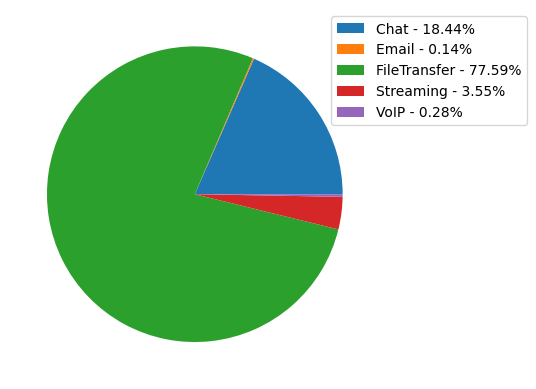

----------------------------------------------------------------------
----------------------------------------------------------------------


----------------------------------------------------------------------
----------------------------------------------------------------------

CLASIFICANDO LA CATEGORIA 'Chat_fotos_5G' DE LOS SEMIFLUJOS A CLASIFICAR

Esta categoria tiene 103 semiflujos

Resultados obtenidos de la clasificación:


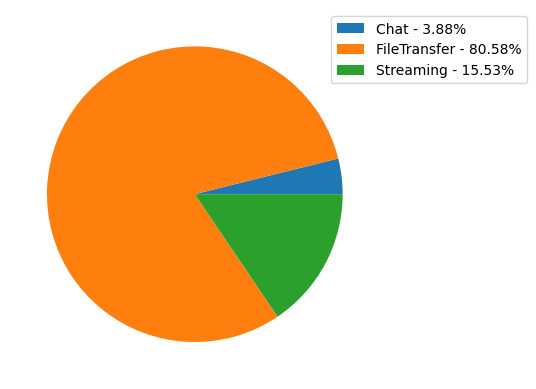

----------------------------------------------------------------------
----------------------------------------------------------------------


----------------------------------------------------------------------
----------------------------------------------------------------------

CLASIFICANDO LA CATEGORIA 'Chat_texto_5G' DE LOS SEMIFLUJOS A CLASIFICAR

Esta categoria tiene 187 semiflujos

Resultados obtenidos de la clasificación:


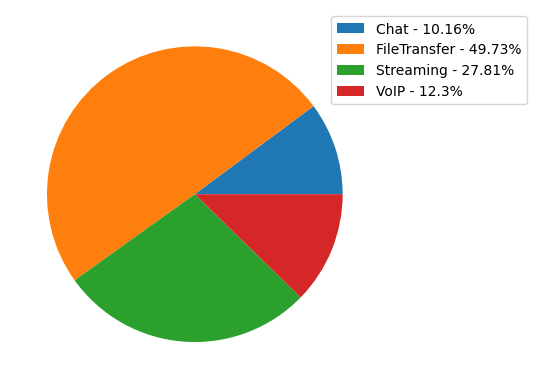

----------------------------------------------------------------------
----------------------------------------------------------------------


----------------------------------------------------------------------
----------------------------------------------------------------------

CLASIFICANDO LA CATEGORIA 'FileTransfer_5G' DE LOS SEMIFLUJOS A CLASIFICAR

Esta categoria tiene 26200 semiflujos

Resultados obtenidos de la clasificación:


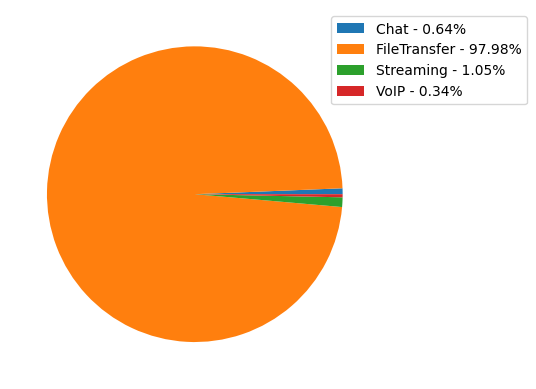

----------------------------------------------------------------------
----------------------------------------------------------------------


----------------------------------------------------------------------
----------------------------------------------------------------------

CLASIFICANDO LA CATEGORIA 'Instagram_5G' DE LOS SEMIFLUJOS A CLASIFICAR

Esta categoria tiene 430 semiflujos

Resultados obtenidos de la clasificación:


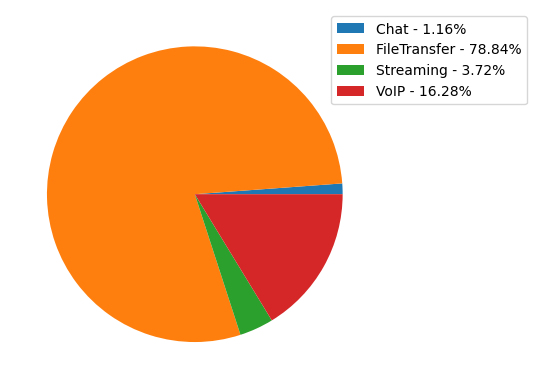

----------------------------------------------------------------------
----------------------------------------------------------------------


----------------------------------------------------------------------
----------------------------------------------------------------------

CLASIFICANDO LA CATEGORIA 'Maps_5G' DE LOS SEMIFLUJOS A CLASIFICAR

Esta categoria tiene 478 semiflujos

Resultados obtenidos de la clasificación:


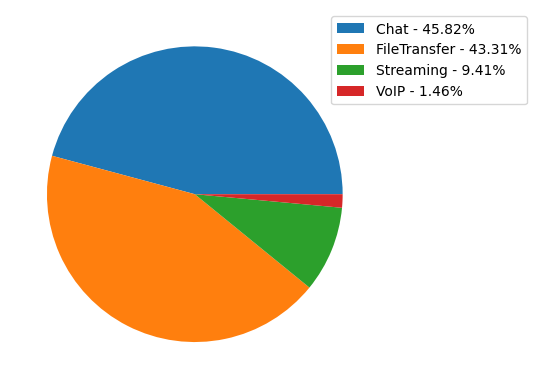

----------------------------------------------------------------------
----------------------------------------------------------------------


----------------------------------------------------------------------
----------------------------------------------------------------------

CLASIFICANDO LA CATEGORIA 'Streaming_5G' DE LOS SEMIFLUJOS A CLASIFICAR

Esta categoria tiene 3300 semiflujos

Resultados obtenidos de la clasificación:


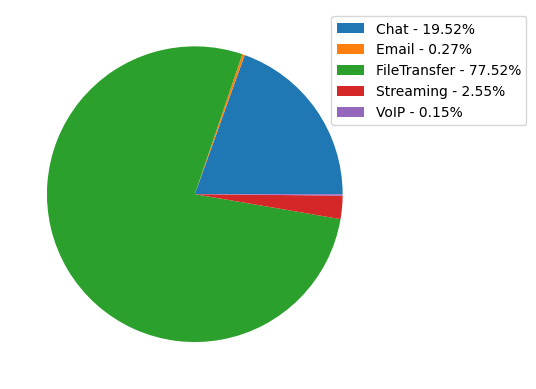

----------------------------------------------------------------------
----------------------------------------------------------------------


----------------------------------------------------------------------
----------------------------------------------------------------------

CLASIFICANDO LA CATEGORIA 'Videojuego_5G' DE LOS SEMIFLUJOS A CLASIFICAR

Esta categoria tiene 391 semiflujos

Resultados obtenidos de la clasificación:


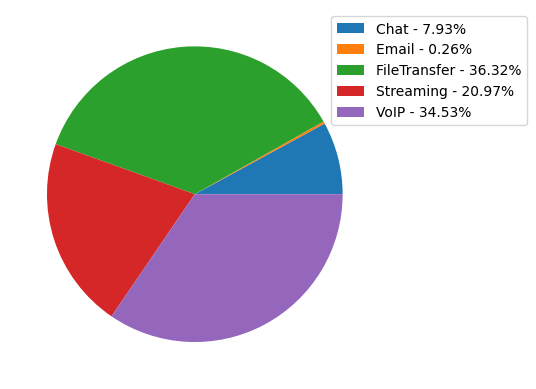

----------------------------------------------------------------------
----------------------------------------------------------------------


In [11]:
primero = 0 

for key in diccionario_semiflujos:
    ultimo = primero + diccionario_semiflujos[key]
    
    print("\n\n----------------------------------------------------------------------")
    print("----------------------------------------------------------------------")
    print("\nCLASIFICANDO LA CATEGORIA '"+key+"' DE LOS SEMIFLUJOS A CLASIFICAR")
    #print("\nLos indices de la categoria "+key+" van desde "+str(primero)+" hasta "+str(ultimo))
    print("\nEsta categoria tiene "+str(diccionario_semiflujos[key])+" semiflujos")
    
    
    
    ## Realizamos la prediccion del modelo sobre los semiflujos de esta categoria
    prediccion_categoria = model.predict(array_semiflujos[primero:ultimo],batch_size=batch_size,verbose=0)
    
    ## Elegimos la clase ganadora, ya que le modelo devuelve probabilidad, asi que nos quedamos con la
    ## clase que tiene más probabilidad como ganadora
    prediccion_categoria_transformado = np.argmax(prediccion_categoria,axis=1)
    
    values, counts = np.unique(prediccion_categoria_transformado, return_counts=True)
    
    ## En values tenemos las categorias que han sido predichas, y en counts cuántos semiflujos por categoria
    ## Ej: values = [0,2,3] y counts = [10,15,5]
    ## El modelo habría identificado 10 semiflujos como categoria 0, 15 como categoria 2 y 5 como categoria 3
    
    ## Vamos a poner nombre a las categorias de values, es decir, cambiar el número por la clase de tráfico a
    ## a la que representan
    
    labels_categorias = []

    for valor in values:
        labels_categorias.append(clases_clasificador[valor])
        
    lista_porcentajes = list()
    for item in counts:
        total = sum(counts)
        val = round(item/total*100,2)
        lista_porcentajes.append(val)
    
    plt.pie(counts)
    
    labels = ['%s - %s%%' % (l, s) for l, s in zip(labels_categorias, lista_porcentajes)]
    plt.legend(bbox_to_anchor=(0.85, 1), loc='upper left', labels=labels)
    
    print("\nResultados obtenidos de la clasificación:")   
    plt.show() 
    
    print("----------------------------------------------------------------------")
    print("----------------------------------------------------------------------")
    
    primero += diccionario_semiflujos[key]

## ------------------------------------- 🎉 FIN DEL NOTEBOOK 🎉 -------------------------------------